# What Drives a High Data-Science Salary?
**Classification of 151K data / ML / AI job salaries (2020–2025)**

**Research question:** Which job attributes (experience level, role, company size, location, remote ratio, employment type) best predict whether a data-science job pays above the median salary?

**Label:** `high_salary` = 1 if `salary_in_usd` > median, else 0 (balanced by construction).

Outline: 1) data & EDA · 2) feature engineering · 3) supervised learning (6 classifiers) · 4) unsupervised learning (PCA, K-means) · 5) findings

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, cohen_kappa_score, make_scorer, roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
SEED = 42

## 1. Data and exploratory analysis

In [2]:
df = pd.read_csv("../data/salaries.csv")
print(df.shape)
df.head()

(151445, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M


In [3]:
median_salary = df["salary_in_usd"].median()
print(f"Median salary: ${median_salary:,.0f}")
print(df["salary_in_usd"].describe().apply(lambda v: f"{v:,.0f}"))
print(f"Skewness: {df['salary_in_usd'].skew():.2f}")
q1, q3 = df["salary_in_usd"].quantile([.25, .75])
out = ((df["salary_in_usd"] < q1 - 1.5*(q3-q1)) | (df["salary_in_usd"] > q3 + 1.5*(q3-q1))).mean()
print(f"IQR outliers in salary_in_usd: {out:.1%}")

Median salary: $146,100
count    151,445
mean     157,527
std       74,151
min       15,000
25%      105,800
50%      146,100
75%      198,000
max      800,000
Name: salary_in_usd, dtype: object
Skewness: 1.35
IQR outliers in salary_in_usd: 2.2%


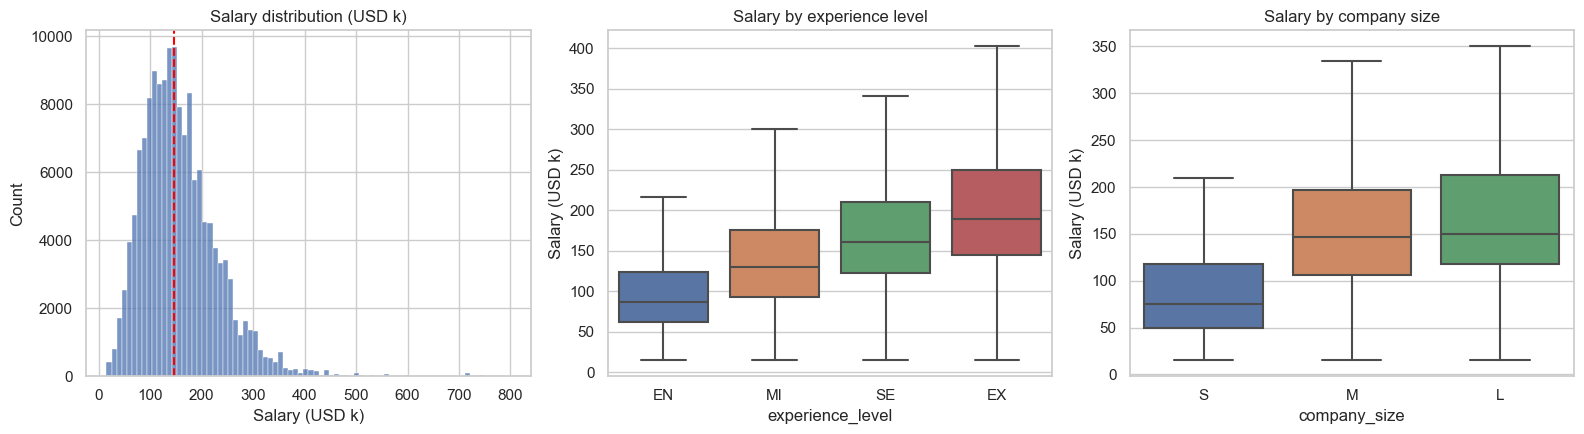

In [4]:
order_exp = ["EN", "MI", "SE", "EX"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df["salary_in_usd"]/1000, bins=80, ax=axes[0]); axes[0].axvline(median_salary/1000, color="red", ls="--")
axes[0].set(title="Salary distribution (USD k)", xlabel="Salary (USD k)")
sns.boxplot(data=df, x="experience_level", y=df["salary_in_usd"]/1000, order=order_exp, showfliers=False, ax=axes[1])
axes[1].set(title="Salary by experience level", ylabel="Salary (USD k)")
sns.boxplot(data=df, x="company_size", y=df["salary_in_usd"]/1000, order=["S","M","L"], showfliers=False, ax=axes[2])
axes[2].set(title="Salary by company size", ylabel="Salary (USD k)")
plt.tight_layout(); plt.savefig(FIG/"eda_salary.png", dpi=130); plt.show()

In [5]:
summary = []
for col in ["experience_level", "company_size", "remote_ratio", "employment_type", "work_year"]:
    s = df.groupby(col)["salary_in_usd"].agg(n="size", median="median")
    s["share_high"] = df.assign(h=df.salary_in_usd > median_salary).groupby(col)["h"].mean()
    s.index = [f"{col}={i}" for i in s.index]
    summary.append(s)
pd.concat(summary).round(3)

,n,median,share_high
experience_level=EN,13663,86600.0,0.146
experience_level=EX,4163,189370.0,0.735
experience_level=MI,46128,130000.0,0.394
experience_level=SE,87491,161000.0,0.600
company_size=L,3926,149800.0,0.503
company_size=M,147302,146400.0,0.500
company_size=S,217,75000.0,0.129
remote_ratio=0,119570,147000.0,0.503
remote_ratio=50,329,69999.0,0.085
remote_ratio=100,31546,145000.0,0.492


In [6]:
us_share = (df["company_location"] == "US").mean()
print(f"US-based companies: {us_share:.1%} of postings")
print("High-salary share, US vs non-US:")
print(df.assign(h=df.salary_in_usd > median_salary, us=df.company_location.eq("US")).groupby("us")["h"].mean().round(3))

US-based companies: 89.5% of postings
High-salary share, US vs non-US:
us
False    0.189
True     0.536
Name: h, dtype: float64


## 2. Feature engineering
- `salary` and `salary_currency` are dropped: `salary` is the target in local currency (leakage), and currency is nearly a duplicate of location.
- High-cardinality categoricals are capped: the 25 most common job titles and the 15 most common countries are kept, the rest grouped as `Other`.
- `experience_level` and `company_size` are ordinal-encoded; everything else is one-hot encoded; features are standardized (scaler fit on the training set only).

In [7]:
def top_n(s, n):
    keep = s.value_counts().index[:n]
    return s.where(s.isin(keep), "Other")

X_raw = pd.DataFrame({
    "experience": df["experience_level"].map({"EN":0, "MI":1, "SE":2, "EX":3}),
    "company_size": df["company_size"].map({"S":0, "M":1, "L":2}),
    "remote_ratio": df["remote_ratio"],
    "work_year": df["work_year"],
    "job_title": top_n(df["job_title"], 25),
    "company_location": top_n(df["company_location"], 15),
    "employee_residence_same": (df["employee_residence"] == df["company_location"]).astype(int),
    "employment_type": df["employment_type"],
})
X = pd.get_dummies(X_raw, columns=["job_title", "company_location", "employment_type"], drop_first=True, dtype=int)
y = (df["salary_in_usd"] > median_salary).astype(int).values
print(X.shape, "label balance:", y.mean().round(3))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = scaler.transform(X_tr), scaler.transform(X_te)

(151445, 48) label balance: 0.5


## 3. Supervised learning
Six classifiers are compared with **5-fold stratified cross-validation** on the training set (accuracy and Cohen's κ), then refit and scored on the untouched 20% test set.

In [8]:
models = {
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Linear SVM": LinearSVC(dual=False),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=18, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = {"acc": "accuracy", "kappa": make_scorer(cohen_kappa_score)}
rows = []
for name, m in models.items():
    r = cross_validate(m, Xs_tr, y_tr, cv=cv, scoring=scoring, n_jobs=-1)
    m.fit(Xs_tr, y_tr); p = m.predict(Xs_te)
    rows.append({"model": name,
                 "cv_accuracy": r["test_acc"].mean(), "cv_kappa": r["test_kappa"].mean(),
                 "test_accuracy": accuracy_score(y_te, p), "test_kappa": cohen_kappa_score(y_te, p)})
results = pd.DataFrame(rows).set_index("model").sort_values("cv_accuracy", ascending=False)
results.round(4)

,cv_accuracy,cv_kappa,test_accuracy,test_kappa
model,,,,
Linear SVM,0.6972,0.3945,0.6981,0.3962
Logistic Regression,0.6969,0.3939,0.6986,0.3972
Random Forest,0.6968,0.3937,0.6994,0.3989
AdaBoost,0.6961,0.3921,0.6974,0.3948
Decision Tree,0.6960,0.3920,0.6973,0.3947
Naive Bayes,0.5648,0.1297,0.5689,0.1378


### Hyperparameter tuning for the strongest models

In [9]:
grids = {
    "Random Forest": (RandomForestClassifier(n_jobs=-1, random_state=SEED),
                      {"n_estimators": [200], "max_depth": [12, 18, None], "min_samples_leaf": [1, 5, 20]}),
    "Logistic Regression": (LogisticRegression(max_iter=2000), {"C": [0.01, 0.1, 1, 10]}),
}
tuned = {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(est, grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="accuracy", n_jobs=-1).fit(Xs_tr, y_tr)
    p = gs.predict(Xs_te)
    tuned[name] = gs.best_estimator_
    print(f"{name:20s} best={gs.best_params_}  test acc={accuracy_score(y_te,p):.4f}  kappa={cohen_kappa_score(y_te,p):.4f}")

Random Forest        best={'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}  test acc=0.6987  kappa=0.3974
Logistic Regression  best={'C': 0.01}  test acc=0.6989  kappa=0.3979


Tuned Random Forest test ROC-AUC: 0.7701


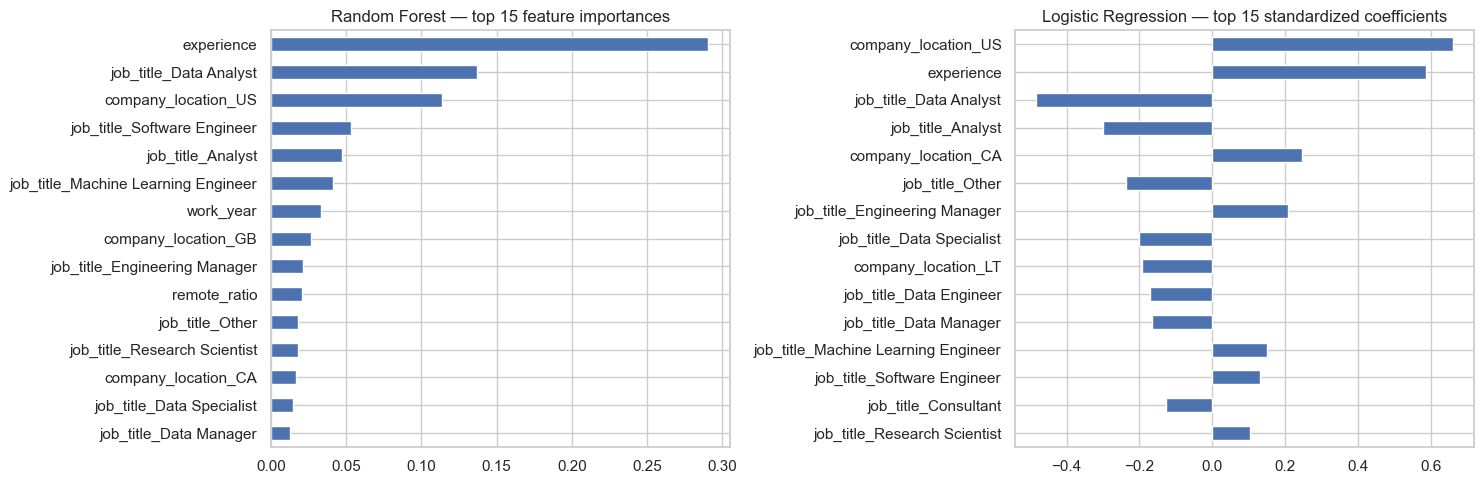

In [10]:
best = tuned["Random Forest"]
auc = roc_auc_score(y_te, best.predict_proba(Xs_te)[:, 1])
print(f"Tuned Random Forest test ROC-AUC: {auc:.4f}")
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
coef = pd.Series(tuned["Logistic Regression"].coef_[0], index=X.columns)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
imp[::-1].plot.barh(ax=axes[0], title="Random Forest — top 15 feature importances")
coef.reindex(coef.abs().sort_values(ascending=False).index[:15])[::-1].plot.barh(ax=axes[1], title="Logistic Regression — top 15 standardized coefficients")
plt.tight_layout(); plt.savefig(FIG/"feature_importance.png", dpi=130); plt.show()

## 4. Unsupervised learning

In [11]:
pca = PCA(n_components=10, random_state=SEED).fit(Xs_tr)
cum = np.cumsum(pca.explained_variance_ratio_)
print(pd.Series(cum, index=range(1, 11), name="cumulative variance").round(3).to_string())
pca2 = PCA(n_components=2, random_state=SEED).fit(Xs_tr)
load = pd.DataFrame(pca2.components_.T, index=X.columns, columns=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    print(f"\n{pc} top loadings:"); print(load[pc].reindex(load[pc].abs().sort_values(ascending=False).index[:6]).round(3).to_string())

1     0.042
2     0.077
3     0.107
4     0.135
5     0.161
6     0.185
7     0.208
8     0.231
9     0.253
10    0.275

PC1 top loadings:
company_location_US      -0.641
company_location_CA       0.371
company_location_GB       0.325
employment_type_FT       -0.237
company_location_Other    0.221
employment_type_PT        0.210

PC2 top loadings:
employment_type_FT    -0.635
employment_type_PT     0.626
company_location_US    0.269
company_location_CA   -0.224
company_location_GB   -0.149
employment_type_FL     0.117


In [12]:
Z_tr, Z_te = pca2.transform(Xs_tr), pca2.transform(Xs_te)
rf_pc = RandomForestClassifier(**{k: v for k, v in tuned["Random Forest"].get_params().items()}).fit(Z_tr, y_tr)
p = rf_pc.predict(Z_te)
print(f"Random Forest on 2 PCs: acc={accuracy_score(y_te,p):.4f} kappa={cohen_kappa_score(y_te,p):.4f}")

Random Forest on 2 PCs: acc=0.6983 kappa=0.3967


In [13]:
rng = np.random.default_rng(SEED)
sample = rng.choice(len(Xs_tr), 20000, replace=False)
ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Xs_tr[sample])
    inertia.append(km.inertia_); sil.append(silhouette_score(Xs_tr[sample], km.labels_, sample_size=5000, random_state=SEED))
print(pd.DataFrame({"k": ks, "inertia": inertia, "silhouette": sil}).round(3).to_string(index=False))

 k    inertia  silhouette
 2 922192.902       0.922
 3 898629.073       0.001
 4 872147.240       0.257
 5 851944.735       0.084
 6 827082.329       0.062
 7 807208.866       0.036
 8 784526.588       0.103


K = 2
         experience  company_size  remote_ratio  company_location_US  high_salary       n
cluster                                                                                  
0             1.569         1.026        20.891                1.000        0.537  108335
1             1.327         1.014        20.669                0.021        0.189   12821


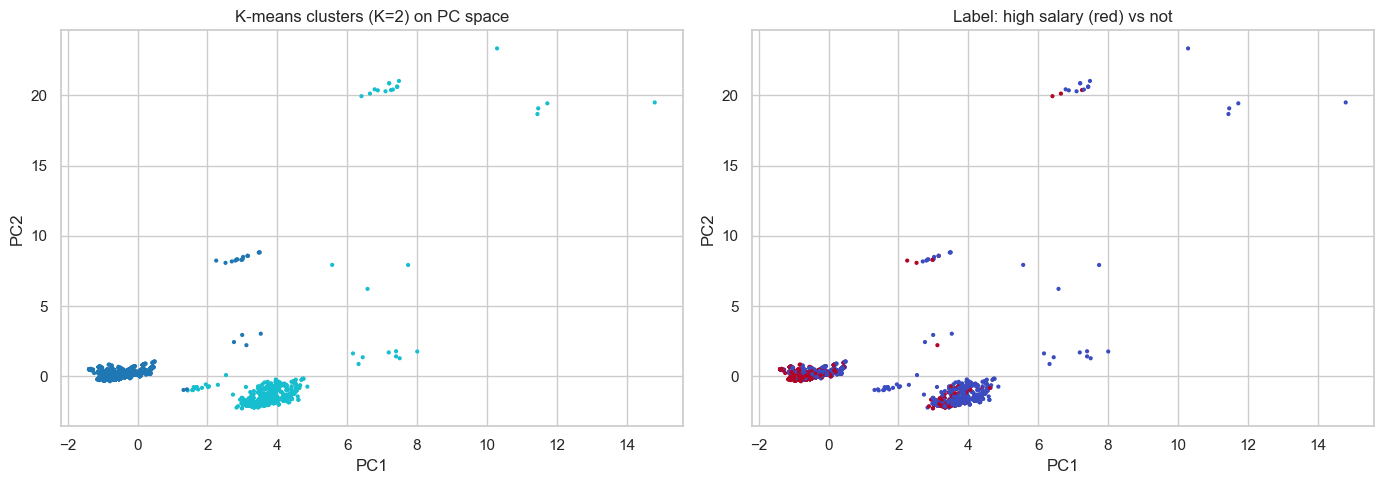

In [14]:
K = int(list(ks)[int(np.argmax(sil))])
km = KMeans(K, n_init=10, random_state=SEED).fit(Xs_tr)
prof = X_tr.assign(cluster=km.labels_, high_salary=y_tr).groupby("cluster")
stats = prof[["experience", "company_size", "remote_ratio", "company_location_US", "high_salary"]].mean()
stats["n"] = prof.size()
print(f"K = {K}"); print(stats.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
idx = sample[:8000]
ax[0].scatter(Z_tr[idx,0], Z_tr[idx,1], c=km.labels_[idx], s=4, cmap="tab10"); ax[0].set(title=f"K-means clusters (K={K}) on PC space", xlabel="PC1", ylabel="PC2")
ax[1].scatter(Z_tr[idx,0], Z_tr[idx,1], c=y_tr[idx], s=4, cmap="coolwarm"); ax[1].set(title="Label: high salary (red) vs not", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.savefig(FIG/"clusters.png", dpi=130); plt.show()

## 5. Findings
1. **Experience level and company location dominate.** Executive roles are above the median 74% of the time vs. 15% for entry-level; US-based companies 54% vs. 19% elsewhere. Job title adds signal (e.g. *Data Analyst* titles are strongly negative; *ML Engineer*, *Engineering Manager* positive).
2. **Model ceiling ≈ 70% accuracy (κ ≈ 0.40, ROC-AUC 0.77).** Five of six classifiers land within 0.2 pp of each other — the limit is the information in the features (no skills, industry, or seniority detail), not model capacity. Gaussian Naive Bayes lags (57%) because its independence/normality assumptions fit one-hot data poorly.
3. **Two principal components retain the predictive signal** (RF accuracy 69.8% on 2 PCs vs. 69.9% on all 48 features) because PC1 is essentially *US vs. non-US* — even though the 2 PCs explain only 7.7% of feature variance.
4. **K-means finds a near-perfect 2-cluster split (silhouette 0.92) that is simply US vs. non-US companies**, with high-salary shares of 54% and 19% — a reminder that unsupervised structure here reflects the dataset's geographic composition (90% US) rather than job archetypes.

**Limitations:** self-reported, US-heavy data; salary converted to USD without cost-of-living adjustment; associations are not causal.